In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from scipy.stats import chi2_contingency

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler
from sklearn.feature_selection import VarianceThreshold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, ConfusionMatrixDisplay
)
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

# Global reproducibility seed — used everywhere
SEED = 42

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.4f}'.format)

## 1. Load Dataset

In [ ]:
# Reading dataSet
import pandas as pd
data = pd.read_csv("/content/DataCoSupplyChainDataset.csv", encoding='latin1')

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 53 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  object 
 1   Days for shipping (real)       180519 non-null  int64  
 2   Days for shipment (scheduled)  180519 non-null  int64  
 3   Benefit per order              180519 non-null  float64
 4   Sales per customer             180519 non-null  float64
 5   Delivery Status                180519 non-null  object 
 6   Late_delivery_risk             180519 non-null  int64  
 7   Category Id                    180519 non-null  int64  
 8   Category Name                  180519 non-null  object 
 9   Customer City                  180519 non-null  object 
 10  Customer Country               180519 non-null  object 
 11  Customer Email                 180519 non-null  object 
 12  Customer Fname                

In [ ]:
# Dataset Overview
data.shape

(180519, 53)

The dataset contains around 180,000 rows and 53 columns, representing individual orders and their shipment details.


## 2. Handling Missing Values

In [ ]:
data.drop('Product Description', axis=1, inplace=True)

I dropped Product Description because it contained 100% missing values .

In [ ]:
data.drop('Order Zipcode', axis=1, inplace=True)

Since the column had 86% missing values, filling it would introduce bias and reduce model performance, so dropping it was the most appropriate decision.

In [ ]:
data['Customer Zipcode'] = data['Customer Zipcode'].fillna(data['Customer Zipcode'].mode()[0])

BECAUSE IT IS CONTAIN 3 MISSING VALUES.

## 3. Exploratory Data Analysis (EDA)

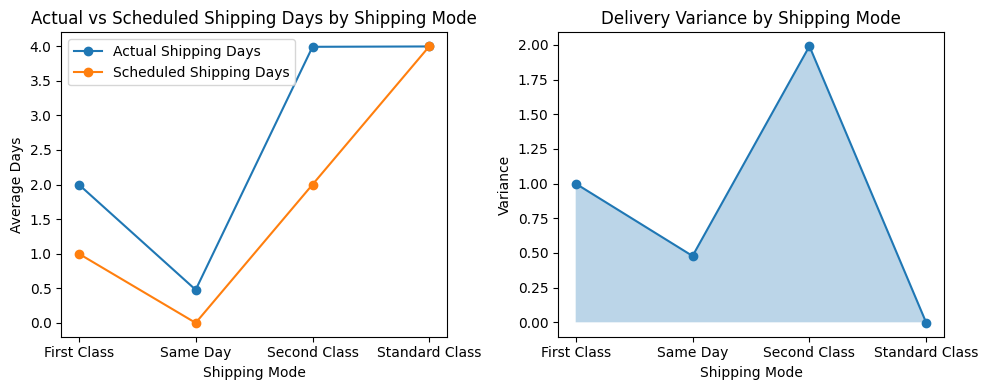

In [ ]:
# Shipping mode analysis: actual and scheduled days
shipping_analysis_df = data[
    ["Shipping Mode", "Days for shipping (real)", "Days for shipment (scheduled)"]
].dropna()

shipping_days = shipping_analysis_df.groupby("Shipping Mode").agg({
    "Days for shipping (real)": "mean",
    "Days for shipment (scheduled)": "mean"
}).reset_index()

shipping_days["Delivery Date Variance"] = (
    shipping_days["Days for shipping (real)"] - shipping_days["Days for shipment (scheduled)"]
)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].plot(shipping_days["Shipping Mode"], shipping_days["Days for shipping (real)"],
           marker="o", label="Actual Shipping Days")
ax[0].plot(shipping_days["Shipping Mode"], shipping_days["Days for shipment (scheduled)"],
           marker="o", label="Scheduled Shipping Days")
ax[0].set_title("Actual vs Scheduled Shipping Days by Shipping Mode")
ax[0].set_xlabel("Shipping Mode")
ax[0].set_ylabel("Average Days")
ax[0].legend()

ax[1].plot(shipping_days["Shipping Mode"], shipping_days["Delivery Date Variance"],
           marker="o", label="Delivery Variance")
ax[1].fill_between(shipping_days["Shipping Mode"], shipping_days["Delivery Date Variance"], alpha=0.3)
ax[1].set_title("Delivery Variance by Shipping Mode")
ax[1].set_xlabel("Shipping Mode")
ax[1].set_ylabel("Variance")

plt.tight_layout()
plt.show()

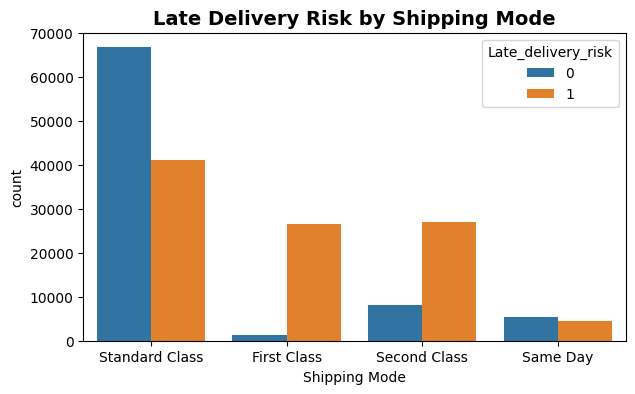

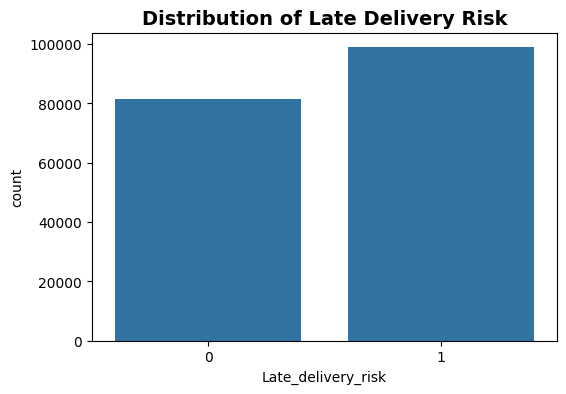

In [ ]:
# Late delivery risk distribution by shipping mode
plt.figure(figsize=(7, 4))
sns.countplot(x="Shipping Mode", hue="Late_delivery_risk", data=data)
plt.title("Late Delivery Risk by Shipping Mode", fontsize=14, fontweight="bold")
plt.show()

# Target variable balance check
plt.figure(figsize=(6, 4))
sns.countplot(x="Late_delivery_risk", data=data)
plt.title("Distribution of Late Delivery Risk", fontsize=14, fontweight="bold")
plt.show()

## 4. Data Preprocessing — Drop Irrelevant / Leakage Columns

In [ ]:
cols_to_drop = [
    # PII / Security
    'Customer Email',
    'Customer Password',
    'Customer Fname',
    'Customer Lname',
    'Customer Street',
    # Unusable
    'Product Image',
    # Redundant — represented by ID columns
    'Category Name',
    'Department Name',
    'Order City',
    'Order State',
    'Order Country',
    'Product Name',
    # TARGET LEAKAGE — these directly reveal the outcome
    'Delivery Status',
    'Days for shipping (real)',
    'Order Status',
    # ID columns — no predictive signal
    'Customer Id',
    'Order Id',
    'Order Item Id',
    'Order Customer Id',
    # Numeric noise / geographic
    'Latitude',
    'Longitude',
    'Order Item Profit Ratio',
    'Order Item Product Price',
    # Duplicate/redundant identifiers
    'Product Card Id',
    'Order Item Cardprod Id',
    'Category Id',
    # Duplicate of Order Item Total (lowercase version)
    'order item total',
    'Order Item Total',   # keeping 'Sales per customer' instead
]

data = data.drop(columns=cols_to_drop, errors='ignore')
print(f"Total columns after dropping: {data.shape[1]}")
data.info()

Total columns after dropping: 24
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 24 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  object 
 1   Days for shipment (scheduled)  180519 non-null  int64  
 2   Benefit per order              180519 non-null  float64
 3   Sales per customer             180519 non-null  float64
 4   Late_delivery_risk             180519 non-null  int64  
 5   Customer City                  180519 non-null  object 
 6   Customer Country               180519 non-null  object 
 7   Customer Segment               180519 non-null  object 
 8   Customer State                 180519 non-null  object 
 9   Customer Zipcode               180519 non-null  float64
 10  Department Id                  180519 non-null  int64  
 11  Market                         180519 non-null  object 
 1

In [ ]:
data_cleaned = data.copy()
# Verify no remaining missing values
print("Missing values:", data_cleaned.isnull().sum().sum())

# Drop zero-variance feature
print("Product Status unique values:", data_cleaned['Product Status'].unique())


Missing values: 0
Product Status unique values: [0]


## 5. Numeric Feature Preparation

In [ ]:
# Extract numeric features only
numeric_df = data_cleaned.select_dtypes(include=['number']).copy()

# Drop zero-variance Product Status
clean_numeric_df = numeric_df.drop(columns=['Product Status'], errors='ignore')

print("Numeric feature stats:")
clean_numeric_df.describe()

Numeric feature stats:


,Days for shipment (scheduled),Benefit per order,Sales per customer,Late_delivery_risk,Customer Zipcode,Department Id,Order Item Discount,Order Item Discount Rate,Order Item Quantity,Sales,Order Profit Per Order,Product Category Id,Product Price
count,180519.0000,180519.0000,180519.0000,180519.0000,180519.0000,180519.0000,180519.0000,180519.0000,180519.0000,180519.0000,180519.0000,180519.0000,180519.0000
mean,2.9318,21.9750,183.1076,0.5483,35920.5420,5.4435,20.6647,0.1017,2.1276,203.7721,21.9750,31.8515,141.2325
std,1.3744,104.4335,120.0437,0.4977,37542.4233,1.6292,21.8009,0.0704,1.4535,132.2731,104.4335,15.6401,139.7325
min,0.0000,-4274.9800,7.4900,0.0000,603.0000,2.0000,0.0000,0.0000,1.0000,9.9900,-4274.9800,2.0000,9.9900
25%,2.0000,7.0000,104.3800,0.0000,725.0000,4.0000,5.4000,0.0400,1.0000,119.9800,7.0000,18.0000,50.0000
50%,4.0000,31.5200,163.9900,1.0000,19380.0000,5.0000,14.0000,0.1000,1.0000,199.9200,31.5200,29.0000,59.9900
75%,4.0000,64.8000,247.4000,1.0000,78207.0000,7.0000,29.9900,0.1600,3.0000,299.9500,64.8000,45.0000,199.9900
max,4.0000,911.8000,1939.9900,1.0000,99205.0000,12.0000,500.0000,0.2500,5.0000,1999.9900,911.8000,76.0000,1999.9900


## 6. Feature Selection  (Remove Correlated Features)

In [ ]:
# Drop features with 1.0 Pearson correlation (exact duplicates)
# 'Sales' = 'Order Item Total'
#'Order Profit Per Order' = 'Benefit per order'
# 'Product Category Id' = 'Category Id'
columns_to_drop = [
    'Sales',
    'Order Profit Per Order',
    'Product Category Id',
]

final_numeric_df = clean_numeric_df.drop(columns=columns_to_drop, errors='ignore')

print(f"Original features count: {clean_numeric_df.shape[1]}")
print(f"Optimized features count: {final_numeric_df.shape[1]}")
final_numeric_df.head()

Original features count: 13
Optimized features count: 10


,Days for shipment (scheduled),Benefit per order,Sales per customer,Late_delivery_risk,Customer Zipcode,Department Id,Order Item Discount,Order Item Discount Rate,Order Item Quantity,Product Price
0,4,91.2500,314.6400,0,725.0000,2,13.1100,0.0400,1,327.7500
1,4,-249.0900,311.3600,1,725.0000,2,16.3900,0.0500,1,327.7500
2,4,-247.7800,309.7200,0,95125.0000,2,18.0300,0.0600,1,327.7500
3,4,22.8600,304.8100,0,90027.0000,2,22.9400,0.0700,1,327.7500
4,4,134.2100,298.2500,0,725.0000,2,29.5000,0.0900,1,327.7500


## 7. Outlier Detection & Treatment

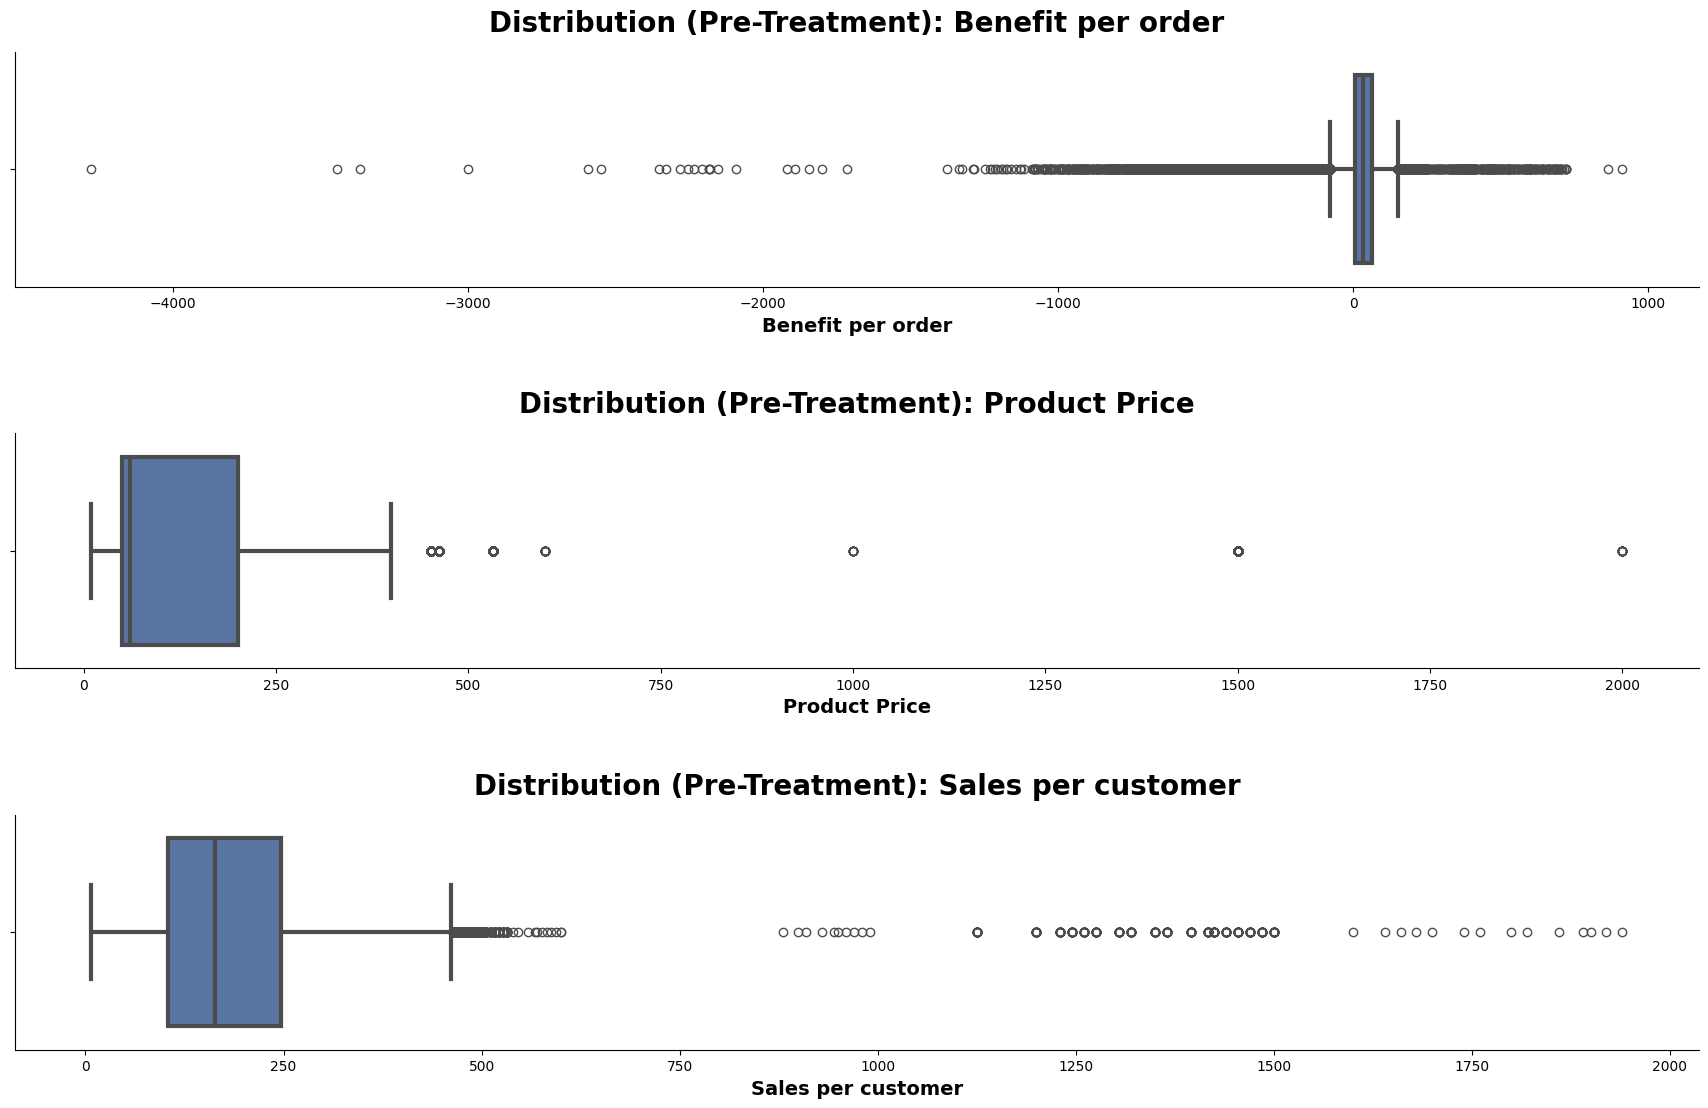

In [ ]:
# Visualize distributions before outlier treatment
target_cols = ['Benefit per order', 'Product Price', 'Sales per customer']

plt.figure(figsize=(18, 12))
for i, col in enumerate(target_cols, 1):
    if col in final_numeric_df.columns:
        plt.subplot(3, 1, i)
        sns.boxplot(x=final_numeric_df[col], color='#4C72B0', linewidth=3, fliersize=6)
        plt.title(f'Distribution (Pre-Treatment): {col}', fontsize=20, fontweight='bold', pad=15)
        plt.xlabel(col, fontsize=14, fontweight='bold')
        sns.despine()
plt.tight_layout(pad=4)
plt.show()

- Benefit per order: 18942 outliers found
- Product Price: 2048 outliers found
- Sales per customer: 1943 outliers found

Outliers replaced with median values.


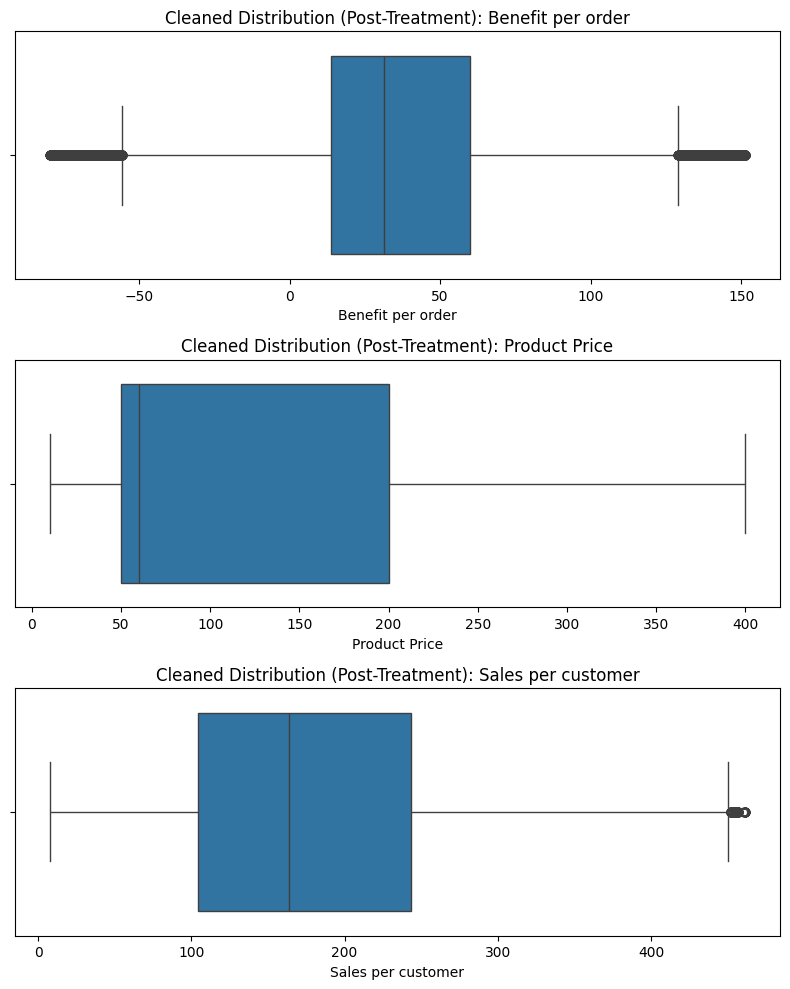

In [ ]:
def get_iqr_outlier_mask(data_series):
    """Return boolean mask of IQR outliers."""
    Q1, Q3 = data_series.quantile(0.25), data_series.quantile(0.75)
    IQR = Q3 - Q1
    return (data_series < Q1 - 1.5 * IQR) | (data_series > Q3 + 1.5 * IQR)

# Detect and replace outliers with median
for col in ['Benefit per order', 'Product Price', 'Sales per customer']:
    mask = get_iqr_outlier_mask(final_numeric_df[col])
    print(f"- {col}: {mask.sum()} outliers found")
    final_numeric_df.loc[mask, col] = final_numeric_df[col].median()

print("\nOutliers replaced with median values.")

# Visualize after treatment
fig, axes = plt.subplots(3, 1, figsize=(8, 10))
for i, col in enumerate(['Benefit per order', 'Product Price', 'Sales per customer']):
    sns.boxplot(x=final_numeric_df[col], ax=axes[i])
    axes[i].set_title(f"Cleaned Distribution (Post-Treatment): {col}")
plt.tight_layout()
plt.show()

## 8. Build Final Model Data (Raw — Before Encoding)

In [ ]:
# Categorical columns to encode via OHE
categorical_cols_to_encode = [
    'Type', 'Customer Segment', 'Market',
    'Shipping Mode', 'Customer City', 'Customer State', 'Order Region'
]

# Save for use after split
joblib.dump(categorical_cols_to_encode, "ohe_categorical_cols.pkl")

# Drop columns not needed in model
cols_to_exclude = ['Customer Zipcode', 'Department Id']
final_numeric_df = final_numeric_df.drop(columns=cols_to_exclude, errors='ignore')

# Combine numeric  and raw categorical and Target
temp_numeric = final_numeric_df.drop(columns=['Late_delivery_risk'])

final_model_data = pd.concat([
    temp_numeric,
    data_cleaned[categorical_cols_to_encode],
    final_numeric_df['Late_delivery_risk']
], axis=1)

print(f"final_model_data shape (raw, before encoding): {final_model_data.shape}")
display(final_model_data.head())

final_model_data shape (raw, before encoding): (180519, 15)


,Days for shipment (scheduled),Benefit per order,Sales per customer,Order Item Discount,Order Item Discount Rate,Order Item Quantity,Product Price,Type,Customer Segment,Market,Shipping Mode,Customer City,Customer State,Order Region,Late_delivery_risk
0,4,91.2500,314.6400,13.1100,0.0400,1,327.7500,DEBIT,Consumer,Pacific Asia,Standard Class,Caguas,PR,Southeast Asia,0
1,4,31.5200,311.3600,16.3900,0.0500,1,327.7500,TRANSFER,Consumer,Pacific Asia,Standard Class,Caguas,PR,South Asia,1
2,4,31.5200,309.7200,18.0300,0.0600,1,327.7500,CASH,Consumer,Pacific Asia,Standard Class,San Jose,CA,South Asia,0
3,4,22.8600,304.8100,22.9400,0.0700,1,327.7500,DEBIT,Home Office,Pacific Asia,Standard Class,Los Angeles,CA,Oceania,0
4,4,134.2100,298.2500,29.5000,0.0900,1,327.7500,PAYMENT,Corporate,Pacific Asia,Standard Class,Caguas,PR,Oceania,0


## 9. Date Feature Engineering

In [ ]:
order_dt  = pd.to_datetime(data_cleaned['order date (DateOrders)'])
ship_dt   = pd.to_datetime(data_cleaned['shipping date (DateOrders)'])

# Time-based features
final_model_data['order_hour']        = order_dt.dt.hour
final_model_data['ship_hour']         = ship_dt.dt.hour
final_model_data['ship_day_of_week']  = ship_dt.dt.dayofweek
final_model_data['order_day_of_week'] = order_dt.dt.dayofweek
final_model_data['is_weekend']        = (final_model_data['order_day_of_week'] >= 5).astype(int)

print("New date-derived columns:")
print(final_model_data[[
    'order_hour', 'ship_hour', 'ship_day_of_week',
    'order_day_of_week', 'is_weekend'
]].head())


New date-derived columns:
   order_hour  ship_hour  ship_day_of_week  order_day_of_week  is_weekend
0          22         22                 5                  2           0
1          12         12                 3                  5           1
2          12         12                 2                  5           1
3          11         11                 1                  5           1
4          11         11                 0                  5           1


## 10. Train / Test Split

In [ ]:
y = final_model_data['Late_delivery_risk']
X = final_model_data.drop(columns=['Late_delivery_risk'])
print(f"X shape: {X.shape}")

# stratify = y preserves the class distribution of the target variable in train and test sets
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

print(f"X_train: {X_train_raw.shape}  |  X_test: {X_test_raw.shape}")
print(f"Train class balance: {y_train.value_counts(normalize=True).round(3).to_dict()}")
print(f"Test  class balance: {y_test.value_counts(normalize=True).round(3).to_dict()}")

X shape: (180519, 19)
X_train: (144415, 19)  |  X_test: (36104, 19)
Train class balance: {1: 0.548, 0: 0.452}
Test  class balance: {1: 0.548, 0: 0.452}


## 11. Shipping Mode Risk Analysis (Post-Split, Training Reference)

    Shipping Mode  Late_delivery_risk
0     First Class              0.9532
1        Same Day              0.4574
2    Second Class              0.7663
3  Standard Class              0.3807


/tmp/ipykernel_513/874946277.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Shipping Mode", y="Late_delivery_risk", data=shipping_risk, palette="viridis")


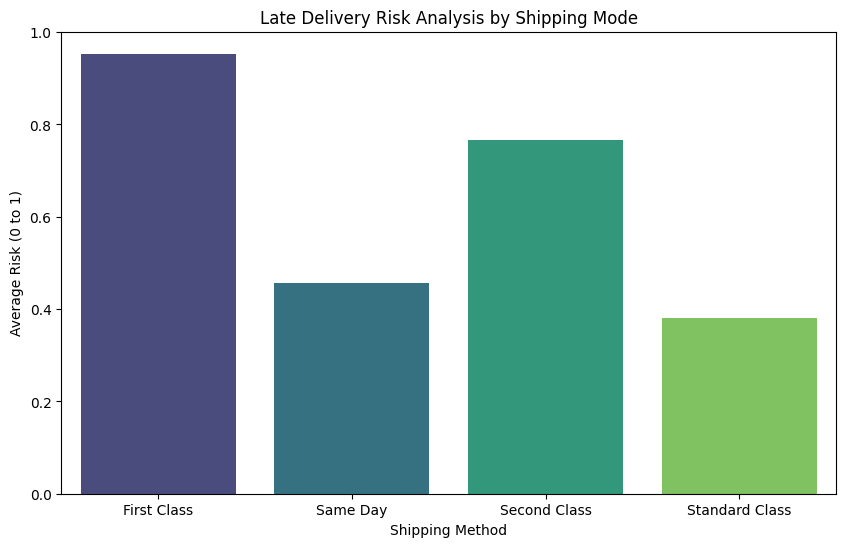

In [ ]:

plot_df = pd.DataFrame({
    'Shipping Mode': data_cleaned['Shipping Mode'],
    'Late_delivery_risk': final_model_data['Late_delivery_risk']
})

shipping_risk = plot_df.groupby("Shipping Mode")["Late_delivery_risk"].mean().reset_index()
print(shipping_risk)

plt.figure(figsize=(10, 6))
sns.barplot(x="Shipping Mode", y="Late_delivery_risk", data=shipping_risk, palette="viridis")
plt.title("Late Delivery Risk Analysis by Shipping Mode")
plt.ylabel("Average Risk (0 to 1)")
plt.xlabel("Shipping Method")
plt.show()

## 12. Correlation Analysis (Training Data Only  No Leakage)

In [ ]:

categorical_cols_to_encode = joblib.load("ohe_categorical_cols.pkl")
numeric_cols_for_corr = [c for c in X_train_raw.columns if c not in categorical_cols_to_encode]

train_numeric_df = X_train_raw[numeric_cols_for_corr].copy()
train_numeric_df["Late_delivery_risk"] = y_train.values  # align index

# Compute once
pearson_corr = train_numeric_df.corr(method='pearson')

print("Feature correlation with target (ranked):")
display(pearson_corr["Late_delivery_risk"].sort_values(ascending=False))

Feature correlation with target (ranked):


,Late_delivery_risk
Late_delivery_risk,1.0000
order_hour,0.0450
ship_day_of_week,0.0028
order_day_of_week,0.0006
Order Item Discount Rate,0.0006
Sales per customer,0.0005
Product Price,0.0002
Order Item Discount,-0.0001
Order Item Quantity,-0.0007
is_weekend,-0.0019


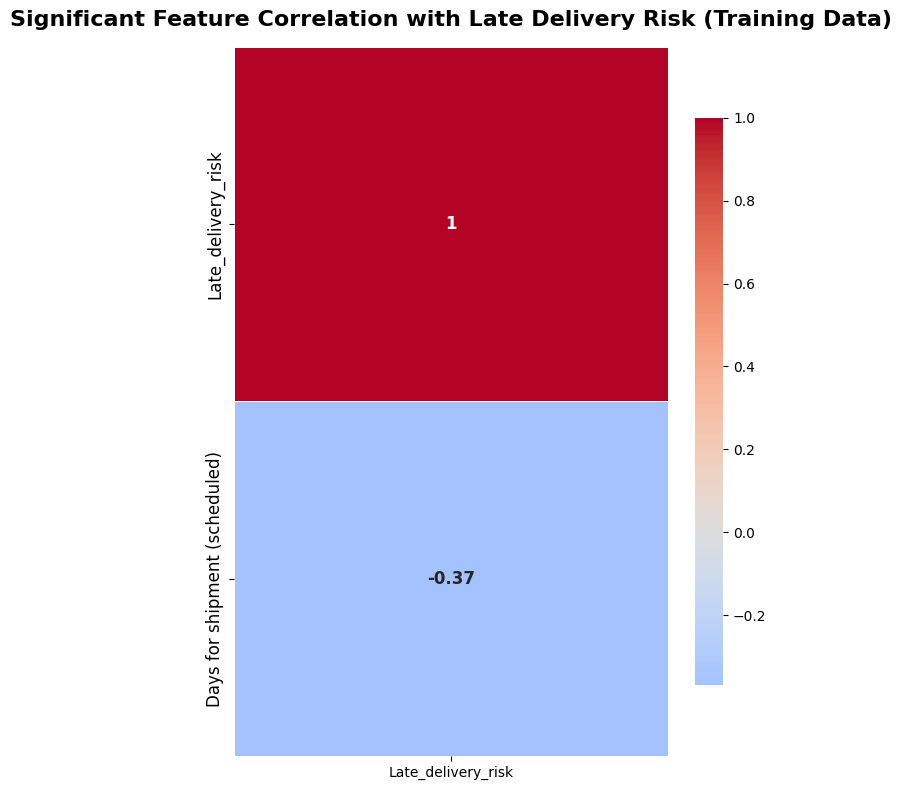

In [ ]:
def plot_target_correlation_heatmap(corr_matrix, target="Late_delivery_risk", threshold=0.05):
    """Plot significant feature correlations with the target variable."""
    corr_with_target = corr_matrix[target].sort_values(ascending=False)
    significant_corr = corr_with_target[abs(corr_with_target) >= threshold].to_frame()

    plt.figure(figsize=(6, 8))
    sns.heatmap(
        significant_corr, annot=True, cmap="coolwarm", center=0,
        linewidths=0.5, annot_kws={"size": 12, "weight": "bold"},
        cbar_kws={"shrink": 0.8}
    )
    plt.title(
        "Significant Feature Correlation with Late Delivery Risk (Training Data)",
        fontsize=16, fontweight="bold", pad=15
    )
    plt.yticks(fontsize=12)
    plt.tight_layout()
    plt.show()

# Pass the already-computed matrix — no second .corr() call
plot_target_correlation_heatmap(pearson_corr)

## 13. Categorical Feature Selection — Chi-Square (Training Data Only)

In [ ]:
categorical_cols_to_encode = joblib.load("ohe_categorical_cols.pkl")
X_categorical_train = X_train_raw[categorical_cols_to_encode].copy()
y_categorical_train = y_train.copy()

chi_results = []
for col in X_categorical_train.columns:
    contingency_table = pd.crosstab(X_categorical_train[col], y_categorical_train)
    chi2, pval, dof, _ = chi2_contingency(contingency_table)
    chi_results.append({
        'Feature': col,
        'Chi2 Statistic': round(chi2, 3),
        'p-value': round(pval, 4),
        'Significant': 'Yes' if pval < 0.05 else 'No'
    })

chi_results_df = pd.DataFrame(chi_results).sort_values(by='p-value')
print("Chi-Square Test Results for Categorical Features (Training Data):")
display(chi_results_df)

Chi-Square Test Results for Categorical Features (Training Data):


,Feature,Chi2 Statistic,p-value,Significant
0,Type,895.4730,0.0000,Yes
3,Shipping Mode,30096.6490,0.0000,Yes
6,Order Region,66.9570,0.0000,Yes
4,Customer City,1637.3010,0.0000,Yes
5,Customer State,84.1290,0.0004,Yes
2,Market,12.4330,0.0144,Yes
1,Customer Segment,2.3340,0.3113,No


In [ ]:
# Keep only statistically significant features
selected_categorical_features = chi_results_df[
    chi_results_df['Significant'] == 'Yes'
]['Feature'].tolist()

# Ensure Market is included
if 'Market' not in selected_categorical_features:
    selected_categorical_features.append('Market')

print("Final categorical features:", selected_categorical_features)

Final categorical features: ['Type', 'Shipping Mode', 'Order Region', 'Customer City', 'Customer State', 'Market']


## 14. One-Hot Encoding (Fitted on Training Data Only)

In [ ]:
categorical_cols_to_encode = joblib.load("ohe_categorical_cols.pkl")

ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

ohe.fit(X_train_raw[categorical_cols_to_encode])

# Transform both splits using the training-fitted encoder
encoded_train = ohe.transform(X_train_raw[categorical_cols_to_encode])
encoded_test  = ohe.transform(X_test_raw[categorical_cols_to_encode])

encoded_feature_names = ohe.get_feature_names_out(categorical_cols_to_encode)

encoded_train_df = pd.DataFrame(encoded_train, columns=encoded_feature_names, index=X_train_raw.index)
encoded_test_df  = pd.DataFrame(encoded_test,  columns=encoded_feature_names, index=X_test_raw.index)

# Numeric columns: everything except the categorical ones
numeric_cols = [c for c in X_train_raw.columns if c not in categorical_cols_to_encode]

# Combine numeric  and encoded categorical
X_train = pd.concat([X_train_raw[numeric_cols].reset_index(drop=True),
                     encoded_train_df.reset_index(drop=True)], axis=1)
X_test  = pd.concat([X_test_raw[numeric_cols].reset_index(drop=True),
                     encoded_test_df.reset_index(drop=True)], axis=1)

y_train = y_train.reset_index(drop=True)
y_test  = y_test.reset_index(drop=True)


joblib.dump(ohe,                              "one_hot_encoder.pkl")
joblib.dump(encoded_feature_names.tolist(),   "one_hot_feature_names.pkl")
joblib.dump(categorical_cols_to_encode,       "ohe_categorical_cols.pkl")
joblib.dump(numeric_cols,                     "numeric_cols.pkl")

print("OneHotEncoder fitted and saved.")
print(f"X_train shape: {X_train.shape}  |  X_test shape: {X_test.shape}")
display(X_train.head())

OneHotEncoder fitted and saved.
X_train shape: (144415, 660)  |  X_test shape: (36104, 660)


,Days for shipment (scheduled),Benefit per order,Sales per customer,Order Item Discount,Order Item Discount Rate,Order Item Quantity,Product Price,order_hour,ship_hour,ship_day_of_week,order_day_of_week,is_weekend,Type_CASH,Type_DEBIT,Type_PAYMENT,Type_TRANSFER,Customer Segment_Consumer,Customer Segment_Corporate,Customer Segment_Home Office,Market_Africa,Market_Europe,Market_LATAM,Market_Pacific Asia,Market_USCA,Shipping Mode_First Class,Shipping Mode_Same Day,Shipping Mode_Second Class,Shipping Mode_Standard Class,Customer City_Aguadilla,Customer City_Alameda,Customer City_Albany,Customer City_Albuquerque,Customer City_Algonquin,Customer City_Alhambra,Customer City_Allentown,Customer City_Alpharetta,Customer City_Amarillo,Customer City_Anaheim,Customer City_Ann Arbor,Customer City_Annandale,Customer City_Annapolis,Customer City_Antioch,Customer City_Apex,Customer City_Apopka,Customer City_Arecibo,Customer City_Arlington,Customer City_Arlington Heights,Customer City_Asheboro,Customer City_Astoria,Customer City_Atlanta,Customer City_Augusta,Customer City_Aurora,Customer City_Austin,Customer City_Azusa,Customer City_Bakersfield,Customer City_Baldwin Park,Customer City_Ballwin,Customer City_Baltimore,Customer City_Bartlett,Customer City_Bay Shore,Customer City_Bayamon,Customer City_Bayonne,Customer City_Baytown,Customer City_Beaverton,Customer City_Bell Gardens,Customer City_Bellflower,Customer City_Bellingham,Customer City_Beloit,Customer City_Bend,Customer City_Bensalem,Customer City_Berwyn,Customer City_Billings,Customer City_Birmingham,Customer City_Bismarck,Customer City_Blacksburg,Customer City_Bloomfield,Customer City_Bolingbrook,Customer City_Bountiful,Customer City_Bowling Green,Customer City_Brandon,Customer City_Brentwood,Customer City_Bridgeton,Customer City_Brighton,Customer City_Bristol,Customer City_Brockton,Customer City_Broken Arrow,Customer City_Bronx,Customer City_Brooklyn,Customer City_Broomfield,Customer City_Brownsville,Customer City_Buena Park,Customer City_Buffalo,Customer City_Burnsville,Customer City_CA,Customer City_Caguas,Customer City_Campbell,Customer City_Canoga Park,Customer City_Canovanas,Customer City_Canton,Customer City_Canyon Country,Customer City_Carlisle,Customer City_Carlsbad,Customer City_Carmichael,Customer City_Carol Stream,Customer City_Carolina,Customer City_Carrollton,Customer City_Carson,Customer City_Cary,Customer City_Catonsville,Customer City_Cayey,Customer City_Cerritos,Customer City_Chambersburg,Customer City_Chandler,Customer City_Chapel Hill,Customer City_Charlotte,Customer City_Chesapeake,Customer City_Chicago,Customer City_Chicago Heights,Customer City_Chillicothe,Customer City_Chino,Customer City_Chino Hills,Customer City_Chula Vista,Customer City_Cicero,Customer City_Cincinnati,Customer City_Citrus Heights,Customer City_Clarksville,Customer City_Clearfield,Customer City_Clementon,Customer City_Cleveland,Customer City_Clovis,Customer City_College Station,Customer City_Colorado Springs,Customer City_Colton,Customer City_Columbia,Customer City_Columbus,Customer City_Compton,Customer City_Conway,Customer City_Cordova,Customer City_Corona,Customer City_Costa Mesa,Customer City_Crown Point,Customer City_Crystal Lake,Customer City_Cumberland,Customer City_Cupertino,Customer City_Cypress,Customer City_Dallas,Customer City_Daly City,Customer City_Danbury,Customer City_Davis,Customer City_Dayton,Customer City_Dearborn,Customer City_Decatur,Customer City_Del Rio,Customer City_Denton,Customer City_Denver,Customer City_Des Plaines,Customer City_Detroit,Customer City_Diamond Bar,Customer City_Dorchester Center,Customer City_Douglasville,Customer City_Doylestown,Customer City_Dubuque,Customer City_Duluth,Customer City_Dundalk,Customer City_Eagle Pass,Customer City_East Brunswick,Customer City_East Lansing,Customer City_Edinburg,Customer City_Edison,Customer City_El Cajon,Customer City_El Centro,Customer City_El Monte,Customer City_El Paso,Customer City_Elgin,Customer City_Elk Grove,Cust

## 15. Variance Threshold (Training Data Only)

In [ ]:
ohe_feature_names = joblib.load("one_hot_feature_names.pkl")

# Preserve Market OHE columns regardless of variance
market_ohe_cols = [col for col in ohe_feature_names if col.startswith('Market_')]

features_to_filter = X_train.drop(columns=market_ohe_cols, errors='ignore')
market_preserved   = X_train[market_ohe_cols]

# Fit threshold on training data ONLY
selector = VarianceThreshold(threshold=0.05)
selector.fit(features_to_filter)

selected_cols = features_to_filter.columns[selector.get_support()]
removed_cols  = features_to_filter.columns[~selector.get_support()]

final_selected_features_list = list(selected_cols) + list(market_preserved.columns)

print(f"Removed low-variance features: {list(removed_cols)}")

# Apply same selection to both sets
X_train = X_train[final_selected_features_list]
X_test  = X_test[final_selected_features_list]

print(f"X_train after VarianceThreshold: {X_train.shape}")
print(f"X_test  after VarianceThreshold: {X_test.shape}")

Removed low-variance features: ['Order Item Discount Rate', 'Customer City_Aguadilla', 'Customer City_Alameda', 'Customer City_Albany', 'Customer City_Albuquerque', 'Customer City_Algonquin', 'Customer City_Alhambra', 'Customer City_Allentown', 'Customer City_Alpharetta', 'Customer City_Amarillo', 'Customer City_Anaheim', 'Customer City_Ann Arbor', 'Customer City_Annandale', 'Customer City_Annapolis', 'Customer City_Antioch', 'Customer City_Apex', 'Customer City_Apopka', 'Customer City_Arecibo', 'Customer City_Arlington', 'Customer City_Arlington Heights', 'Customer City_Asheboro', 'Customer City_Astoria', 'Customer City_Atlanta', 'Customer City_Augusta', 'Customer City_Aurora', 'Customer City_Austin', 'Customer City_Azusa', 'Customer City_Bakersfield', 'Customer City_Baldwin Park', 'Customer City_Ballwin', 'Customer City_Baltimore', 'Customer City_Bartlett', 'Customer City_Bay Shore', 'Customer City_Bayamon', 'Customer City_Bayonne', 'Customer City_Baytown', 'Customer City_Beaverton',

## 16. Scaling — MinMaxScaler (Training Data Only)

In [ ]:
encoded_feature_names = joblib.load("one_hot_feature_names.pkl")

# Scale numeric columns only — OHE columns are already binary [0,1]
cols_to_scale = [col for col in X_train.columns if col not in encoded_feature_names]

scaler = MinMaxScaler()

# Fit on training data ONLY — transform both
X_train[cols_to_scale] = scaler.fit_transform(X_train[cols_to_scale])
X_test[cols_to_scale]  = scaler.transform(X_test[cols_to_scale])

joblib.dump(scaler,        "scaler.pkl")
joblib.dump(cols_to_scale, "cols_to_scale.pkl")

print("MinMaxScaler fitted on training data and saved.")
print("Data after scaling (all numeric values between 0 and 1):")
display(X_train.head())

MinMaxScaler fitted on training data and saved.
Data after scaling (all numeric values between 0 and 1):


,Days for shipment (scheduled),Benefit per order,Sales per customer,Order Item Discount,Order Item Quantity,Product Price,order_hour,ship_hour,ship_day_of_week,order_day_of_week,is_weekend,Type_CASH,Type_DEBIT,Type_PAYMENT,Type_TRANSFER,Customer Segment_Consumer,Customer Segment_Corporate,Customer Segment_Home Office,Shipping Mode_First Class,Shipping Mode_Same Day,Shipping Mode_Second Class,Shipping Mode_Standard Class,Customer City_Caguas,Customer State_CA,Customer State_NY,Customer State_PR,Order Region_Central America,Order Region_Northern Europe,Order Region_Oceania,Order Region_South America,Order Region_Western Europe,Market_Africa,Market_Europe,Market_LATAM,Market_Pacific Asia,Market_USCA
0,1.0000,0.4466,0.0936,0.0000,0.0000,0.1026,0.0870,0.0870,0.3333,0.6667,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,1.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000,0.0000
1,1.0000,0.4981,0.1982,0.0650,0.0000,0.3077,0.6087,0.6087,0.1667,0.8333,1.0000,0.0000,0.0000,0.0000,1.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000
2,0.2500,0.5318,0.1949,0.0480,0.2500,0.1282,0.8696,0.8696,0.8333,0.5000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000,0.0000
3,0.5000,0.6826,0.3491,0.0680,0.0000,0.4872,0.4783,0.4783,0.5000,0.1667,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000
4,0.5000,0.4813,0.7500,0.1040,0.0000,1.0000,0.7826,0.7826,0.5000,0.6667,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000


In [ ]:
print("Final columns used for training the algorithm (X_train.columns):")
print(X_train.columns.tolist())

Final columns used for training the algorithm (X_train.columns):
['Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Order Item Discount', 'Order Item Quantity', 'Product Price', 'order_hour', 'ship_hour', 'ship_day_of_week', 'order_day_of_week', 'is_weekend', 'Type_CASH', 'Type_DEBIT', 'Type_PAYMENT', 'Type_TRANSFER', 'Customer Segment_Consumer', 'Customer Segment_Corporate', 'Customer Segment_Home Office', 'Shipping Mode_First Class', 'Shipping Mode_Same Day', 'Shipping Mode_Second Class', 'Shipping Mode_Standard Class', 'Customer City_Caguas', 'Customer State_CA', 'Customer State_NY', 'Customer State_PR', 'Order Region_Central America', 'Order Region_Northern Europe', 'Order Region_Oceania', 'Order Region_South America', 'Order Region_Western Europe', 'Market_Africa', 'Market_Europe', 'Market_LATAM', 'Market_Pacific Asia', 'Market_USCA']


## 17. Model Training




Random Forest: was used because it handles both numerical and categorical features effectively and reduces overfitting by combining multiple decision trees.

XGBoost: was selected due to its high predictive performance and built-in regularization that improves model accuracy and stability on structured datasets.

Decision Tree : was applied as a baseline model because it is simple, interpretable, and helps understand how input features influence delivery delay predictions.

Gradient Boosting : was included since it improves prediction accuracy by sequentially correcting previous errors and capturing complex relationships between variables.

 Using multiple algorithms allows comparison of performance and helps select the most suitable model for predicting late delivery risk.


/usr/local/lib/python3.12/dist-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Random Forest Accuracy: 0.9682
best_params: {'n_estimators': 300}
              precision    recall  f1-score   support

           0       0.99      0.94      0.96     16308
           1       0.95      0.99      0.97     19796

    accuracy                           0.97     36104
   macro avg       0.97      0.97      0.97     36104
weighted avg       0.97      0.97      0.97     36104



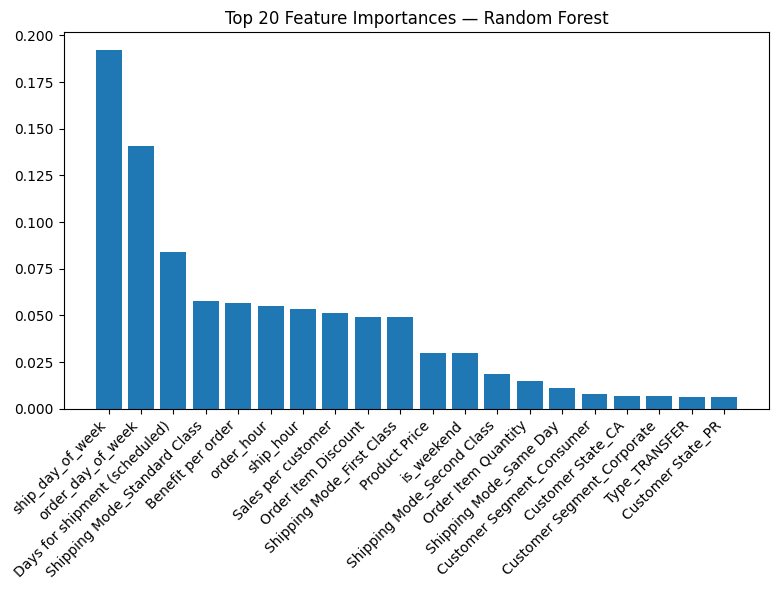

Random Forest model saved.


In [ ]:
# RANDOM FOREST Algorithm

rf_params = {'n_estimators': [50, 100, 150, 200, 300]}

clf_rf = GridSearchCV(
    RandomForestClassifier(random_state=SEED),
    rf_params, cv=5, n_jobs=-1
).fit(X_train, y_train)

best_rf = clf_rf.best_estimator_

y_preds_rf = best_rf.predict(X_test)
print(f"Random Forest Accuracy: {accuracy_score(y_test, y_preds_rf):.4f}")
print(f"best_params: {clf_rf.best_params_}")
print(classification_report(y_test, y_preds_rf))

# Feature importance
feature_importances = pd.Series(
    best_rf.feature_importances_, index=X_train.columns
).sort_values(ascending=False)

plt.figure(figsize=(8, 6))
plt.bar(range(20), feature_importances.values[:20])
plt.xticks(range(20), feature_importances.index[:20], rotation=45, ha='right')
plt.title("Top 20 Feature Importances — Random Forest")
plt.tight_layout()
plt.show()

joblib.dump(best_rf, "random_forest_model.pkl")
print("Random Forest model saved.")

In [ ]:
print("Columns Random Forest model was trained on:")
print(best_rf.feature_names_in_)

Columns Random Forest model was trained on:
['Days for shipment (scheduled)' 'Benefit per order' 'Sales per customer'
 'Order Item Discount' 'Order Item Quantity' 'Product Price' 'order_hour'
 'ship_hour' 'ship_day_of_week' 'order_day_of_week' 'is_weekend'
 'Type_CASH' 'Type_DEBIT' 'Type_PAYMENT' 'Type_TRANSFER'
 'Customer Segment_Consumer' 'Customer Segment_Corporate'
 'Customer Segment_Home Office' 'Shipping Mode_First Class'
 'Shipping Mode_Same Day' 'Shipping Mode_Second Class'
 'Shipping Mode_Standard Class' 'Customer City_Caguas' 'Customer State_CA'
 'Customer State_NY' 'Customer State_PR' 'Order Region_Central America'
 'Order Region_Northern Europe' 'Order Region_Oceania'
 'Order Region_South America' 'Order Region_Western Europe'
 'Market_Africa' 'Market_Europe' 'Market_LATAM' 'Market_Pacific Asia'
 'Market_USCA']


In [37]:
#  GRADIENT BOOSTING Algorithm
gb_params = {
    'n_estimators': [50, 100, 150],
    'learning_rate': [0.01, 0.1, 0.2],
    'max_depth': [3, 5, 7]
}

clf_gb = GridSearchCV(
    GradientBoostingClassifier(random_state=SEED),
    gb_params, cv=5, n_jobs=-1
).fit(X_train, y_train)

best_gb = clf_gb.best_estimator_

y_preds_gb = best_gb.predict(X_test)
print(f"[Gradient Boosting] Accuracy: {accuracy_score(y_test, y_preds_gb):.4f}")
print(f"Best params: {clf_gb.best_params_}")
print(classification_report(y_test, y_preds_gb))

# Cross-validation on training set
cv_scores = cross_val_score(best_gb, X_train, y_train, cv=5)
print(f"CV scores: {cv_scores}  |  Mean: {cv_scores.mean():.4f}")

joblib.dump(best_gb, "gradient_boosting_model.pkl")
print("Gradient Boosting model saved.")

[Gradient Boosting] Accuracy: 0.9745
Best params: {'learning_rate': 0.2, 'max_depth': 7, 'n_estimators': 150}
              precision    recall  f1-score   support

           0       1.00      0.95      0.97     16308
           1       0.96      1.00      0.98     19796

    accuracy                           0.97     36104
   macro avg       0.98      0.97      0.97     36104
weighted avg       0.98      0.97      0.97     36104

CV scores: [0.97707994 0.97559118 0.9756258  0.9770107  0.97382543]  |  Mean: 0.9758
Gradient Boosting model saved.


In [38]:
# DECISION TREE Algorithm
dt_params = {
    'max_depth': [5, 10, 15, 20, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

clf_dt = GridSearchCV(
    DecisionTreeClassifier(random_state=SEED),
    dt_params, cv=5, n_jobs=-1
).fit(X_train, y_train)

best_dt = clf_dt.best_estimator_

y_preds_dt = best_dt.predict(X_test)
print(f"[Decision Tree] Accuracy: {accuracy_score(y_test, y_preds_dt):.4f}")
print(f"Best params: {clf_dt.best_params_}")
print(classification_report(y_test, y_preds_dt))

joblib.dump(best_dt, "decision_tree_model.pkl")
print("Decision Tree model saved.")

[Decision Tree] Accuracy: 0.9549
Best params: {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2}
              precision    recall  f1-score   support

           0       0.95      0.95      0.95     16308
           1       0.96      0.96      0.96     19796

    accuracy                           0.95     36104
   macro avg       0.95      0.95      0.95     36104
weighted avg       0.95      0.95      0.95     36104

Decision Tree model saved.


In [39]:
#  XGBOOST Algorithm
xgb_param_grid = {
    'n_estimators': [300, 500],
    'max_depth': [10, 12, 15],
    'learning_rate': [0.01, 0.05],
    'subsample': [0.8, 0.9]
}

xgb_grid_search = GridSearchCV(
    XGBClassifier(eval_metric='logloss', random_state=SEED),
    xgb_param_grid, cv=3, scoring='accuracy', n_jobs=-1
).fit(X_train, y_train)

best_xgb = xgb_grid_search.best_estimator_

print(f"[XGBoost] Best CV accuracy: {xgb_grid_search.best_score_ * 100:.2f}%")
print(f"Best params: {xgb_grid_search.best_params_}")

y_preds_xgb = best_xgb.predict(X_test)
print(f"Test accuracy: {accuracy_score(y_test, y_preds_xgb):.4f}")
print(classification_report(y_test, y_preds_xgb))

joblib.dump(best_xgb, "XG_BOOST.pkl")
print("XGBoost model (best from grid search) saved.")

[XGBoost] Best CV accuracy: 97.66%
Best params: {'learning_rate': 0.05, 'max_depth': 15, 'n_estimators': 300, 'subsample': 0.9}
Test accuracy: 0.9763
              precision    recall  f1-score   support

           0       1.00      0.95      0.97     16308
           1       0.96      1.00      0.98     19796

    accuracy                           0.98     36104
   macro avg       0.98      0.97      0.98     36104
weighted avg       0.98      0.98      0.98     36104

XGBoost model (best from grid search) saved.


## 18. Final Pipeline ( XGBoost )

<Figure size 800x600 with 0 Axes>

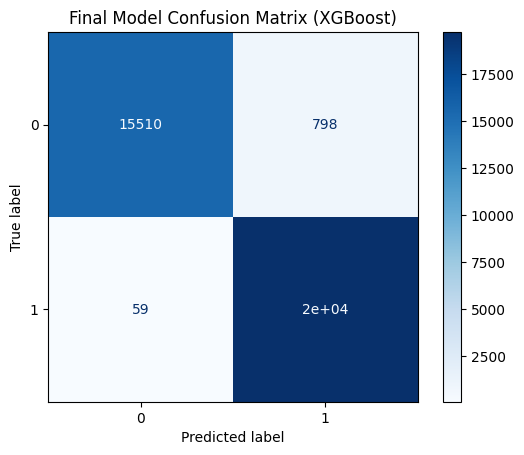

Final Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.95      0.97     16308
           1       0.96      1.00      0.98     19796

    accuracy                           0.98     36104
   macro avg       0.98      0.97      0.98     36104
weighted avg       0.98      0.98      0.98     36104


 Overfit / Underfit Diagnostic: 


,Model,Train,Test,Gap,Verdict
0,Random Forest,1.0000,0.9682,0.0318,OK
1,Gradient Boosting,0.9839,0.9745,0.0094,OK
2,Decision Tree,1.0000,0.9549,0.0451,OK
3,XGBoost,1.0000,0.9763,0.0237,OK


Final pipeline saved as late_delivery_model.pkl


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [40]:

pipeline = Pipeline([
    ("model", best_xgb)
])

pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)

# Confusion matrix
plt.figure(figsize=(8, 6))
ConfusionMatrixDisplay.from_estimator(pipeline, X_test, y_test, cmap='Blues')
plt.title('Final Model Confusion Matrix (XGBoost)')
plt.show()

print("Final Classification Report:")
print(classification_report(y_test, y_pred))

# OVERFIT And UNDERFIT DIAGNOSTIC

# Compare train and test accuracy across all models.
# Rule of thumb:
# gap > 0.05  > overfitting (model memorizes train)
# both low    > underfitting (model too simple / bad features)
# both equal and high > healthy generalisation

print("\n Overfit / Underfit Diagnostic: ")
diag = []
for name, mdl in [("Random Forest", best_rf),
                  ("Gradient Boosting", best_gb),
                  ("Decision Tree", best_dt),
                  ("XGBoost", best_xgb)]:
    train_acc = mdl.score(X_train, y_train)
    test_acc  = mdl.score(X_test,  y_test)
    gap       = train_acc - test_acc
    if gap > 0.05:
        verdict = "OVERFIT"
    elif test_acc < 0.65:
        verdict = "UNDERFIT"
    else:
        verdict = "OK"
    diag.append({"Model": name, "Train": round(train_acc,4),
                 "Test": round(test_acc,4), "Gap": round(gap,4),
                 "Verdict": verdict})
diag_df = pd.DataFrame(diag)
display(diag_df)

# Save the final pipeline
joblib.dump(pipeline, "late_delivery_model.pkl")
print("Final pipeline saved as late_delivery_model.pkl")

from google.colab import files
files.download("late_delivery_model.pkl")


In [41]:
import joblib

pipeline = joblib.load("late_delivery_model.pkl")

model = pipeline.named_steps["model"]

model.get_booster().feature_names

['Days for shipment (scheduled)',
 'Benefit per order',
 'Sales per customer',
 'Order Item Discount',
 'Order Item Quantity',
 'Product Price',
 'order_hour',
 'ship_hour',
 'ship_day_of_week',
 'order_day_of_week',
 'is_weekend',
 'Type_CASH',
 'Type_DEBIT',
 'Type_PAYMENT',
 'Type_TRANSFER',
 'Customer Segment_Consumer',
 'Customer Segment_Corporate',
 'Customer Segment_Home Office',
 'Shipping Mode_First Class',
 'Shipping Mode_Same Day',
 'Shipping Mode_Second Class',
 'Shipping Mode_Standard Class',
 'Customer City_Caguas',
 'Customer State_CA',
 'Customer State_NY',
 'Customer State_PR',
 'Order Region_Central America',
 'Order Region_Northern Europe',
 'Order Region_Oceania',
 'Order Region_South America',
 'Order Region_Western Europe',
 'Market_Africa',
 'Market_Europe',
 'Market_LATAM',
 'Market_Pacific Asia',
 'Market_USCA']

## 19. Model Comparison

,Model,Accuracy,Precision,Recall,F1 Score
3,XGBoost,0.9763,0.9611,0.9970,0.9788
1,Gradient Boosting,0.9745,0.9579,0.9974,0.9772
0,Random Forest,0.9682,0.9535,0.9903,0.9716
2,Decision Tree,0.9549,0.9579,0.9598,0.9589


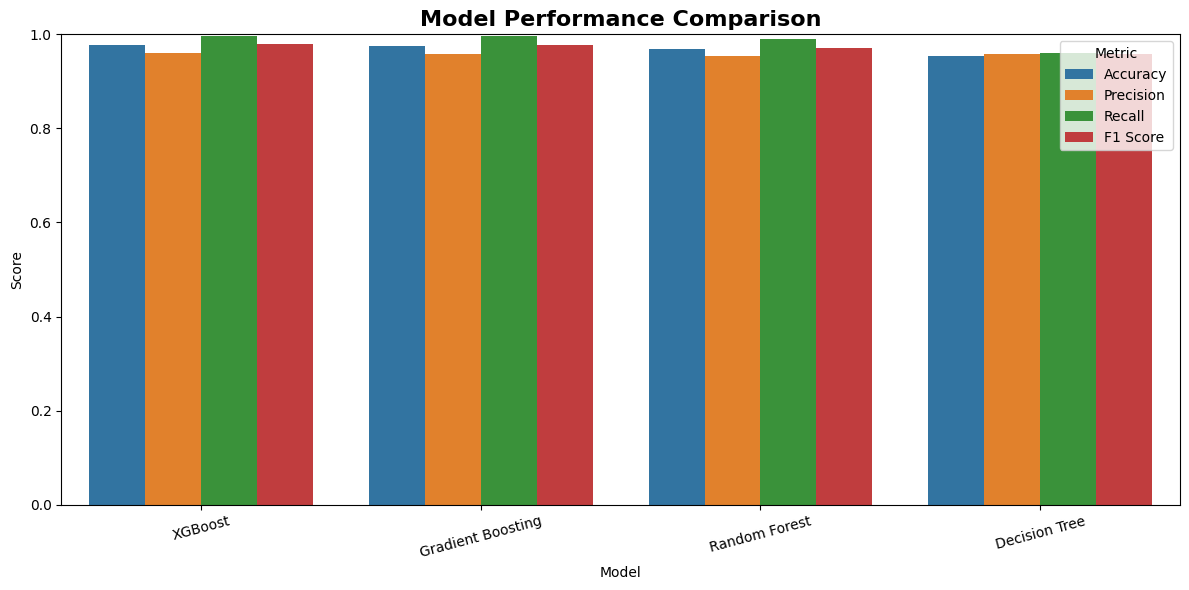

In [42]:


models = {
    "Random Forest":    best_rf,
    "Gradient Boosting": best_gb,
    "Decision Tree":    best_dt,
    "XGBoost":          best_xgb,

}

results = []
for name, model in models.items():
    y_pred_m = model.predict(X_test)
    results.append({
        "Model":     name,
        "Accuracy":  accuracy_score(y_test, y_pred_m),
        "Precision": precision_score(y_test, y_pred_m),
        "Recall":    recall_score(y_test, y_pred_m),
        "F1 Score":  f1_score(y_test, y_pred_m)
    })

results_df = pd.DataFrame(results).sort_values('F1 Score', ascending=False)
display(results_df)

results_melted = results_df.melt(id_vars="Model", var_name="Metric", value_name="Score")

plt.figure(figsize=(12, 6))
sns.barplot(data=results_melted, x="Model", y="Score", hue="Metric")
plt.title("Model Performance Comparison", fontsize=16, fontweight="bold")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(title="Metric")
plt.tight_layout()
plt.show()

## 20. Manual Prediction Test Cases

In [43]:


loaded_ohe           = joblib.load("one_hot_encoder.pkl")
loaded_scaler        = joblib.load("scaler.pkl")
loaded_numeric_cols  = joblib.load("numeric_cols.pkl")
loaded_cat_cols      = joblib.load("ohe_categorical_cols.pkl")
loaded_cols_to_scale = joblib.load("cols_to_scale.pkl")
loaded_ohe_names     = joblib.load("one_hot_feature_names.pkl")

def preprocess_test_case(raw_dict):
    """Apply the same preprocessing pipeline to a raw dict of features."""
    df = pd.DataFrame([raw_dict])

    #  OHE
    cat_df = df[loaded_cat_cols] if all(c in df.columns for c in loaded_cat_cols) else \
             pd.DataFrame([[df.get(c, X_train_raw[c].mode()[0]) for c in loaded_cat_cols]],
                           columns=loaded_cat_cols)
    encoded = loaded_ohe.transform(cat_df)
    encoded_df = pd.DataFrame(encoded, columns=loaded_ohe_names)

    # Numeric
    num_df = pd.DataFrame([[raw_dict.get(c, X_train_raw[c].mean()) for c in loaded_numeric_cols]])

    #  Combine
    combined = pd.concat([num_df, encoded_df], axis=1)

    # Keep only selected features
    combined = combined.reindex(columns=X_train.columns, fill_value=0)

    # Scale numeric
    combined[loaded_cols_to_scale] = loaded_scaler.transform(
        combined[[c for c in loaded_cols_to_scale if c in combined.columns]]
    )

    return combined

raw_test_cases = [

    # Case 1 — Likely ON-TIME
    {
        "Days for shipment (scheduled)": 3,
        "Benefit per order": 15,
        "Sales per customer": 120,
        "Order Item Discount": 5,
        "Order Item Quantity": 2,
        "Product Price": 50,
        "order_hour": 10,
        "ship_hour": 12,
        "ship_day_of_week": 3,
        "order_day_of_week": 2,
        "is_weekend": 0,
        "Type": "DEBIT",
        "Customer Segment": "Consumer",
        "Shipping Mode": "Standard Class",
        "Market": "Pacific Asia",
        "Order Region": "Western Europe",
        "Customer City": "Caguas",
        "Customer State": "PR"
    },

    # Case 2 — Likely LATE
    {
        "Days for shipment (scheduled)": 2,
        "Benefit per order": 40,
        "Sales per customer": 340,
        "Order Item Discount": 20,
        "Order Item Quantity": 5,
        "Product Price": 90,
        "order_hour": 19,
        "ship_hour": 23,
        "ship_day_of_week": 1,
        "order_day_of_week": 5,
        "is_weekend": 1,
        "Type": "TRANSFER",
        "Customer Segment": "Consumer",
        "Shipping Mode": "Second Class",
        "Market": "Pacific Asia",
        "Order Region": "South America",
        "Customer City": "Caguas",
        "Customer State": "PR"
    },

    # Case 3 — Borderline
    {
        "Days for shipment (scheduled)": 4,
        "Benefit per order": 22,
        "Sales per customer": 210,
        "Order Item Discount": 10,
        "Order Item Quantity": 3,
        "Product Price": 70,
        "order_hour": 9,
        "ship_hour": 11,
        "ship_day_of_week": 2,
        "order_day_of_week": 1,
        "is_weekend": 0,
        "Type": "CASH",
        "Customer Segment": "Consumer",
        "Shipping Mode": "First Class",
        "Market": "Pacific Asia",
        "Order Region": "Northern Europe",
        "Customer City": "Caguas",
        "Customer State": "CA"
    },

    # Case 4 — High delay risk
    {
        "Days for shipment (scheduled)": 3,
        "Benefit per order": 55,
        "Sales per customer": 480,
        "Order Item Discount": 25,
        "Order Item Quantity": 6,
        "Product Price": 120,
        "order_hour": 22,
        "ship_hour": 23,
        "ship_day_of_week": 2,
        "order_day_of_week": 6,
        "is_weekend": 1,
        "Type": "DEBIT",
        "Customer Segment": "Home Office",
        "Shipping Mode": "Same Day",
        "Market": "Pacific Asia",
        "Order Region": "Oceania",
        "Customer City": "Caguas",
        "Customer State": "CA"
    }
]
for i, raw in enumerate(raw_test_cases, 1):
    test_input = preprocess_test_case(raw)
    pred = best_xgb.predict(test_input)[0]
    prob = best_xgb.predict_proba(test_input)[0]
    label = "LATE" if pred == 1 else "ON-TIME"
    print(f"Case {i}: {label}  |  P(on-time)={prob[0]:.3f}, P(late)={prob[1]:.3f}")

Case 1: ON-TIME  |  P(on-time)=0.999, P(late)=0.001
Case 2: ON-TIME  |  P(on-time)=0.981, P(late)=0.019
Case 3: LATE  |  P(on-time)=0.007, P(late)=0.993
Case 4: ON-TIME  |  P(on-time)=0.998, P(late)=0.002


## 21. Feature Presence Check

In [44]:
user_features = [
    "Days for shipment (scheduled)",
    "Benefit per order",
    "Sales per customer",
    "Order Item Discount",
    "Order Item Quantity",
    "Product Price",
    "order_hour",
    "ship_hour",
    "ship_day_of_week",
    "order_day_of_week",
    "is_weekend",
    "Type",
    "Customer Segment",
    "Shipping Mode",
    "Market",
    "Order Region",
    "Customer City",
    "Customer State"
]

training_columns = set(X_train.columns)
print(" Feature Check Summary:")
for feature in user_features:
    if feature in training_columns:
        print(f"[OK]     '{feature}' present in X_train.")
    else:
        ohe_matches = [col for col in training_columns if col.startswith(f'{feature}_')]
        if ohe_matches:
            print(f"[OHE]    '{feature}' → encoded as: {ohe_matches[:3]}...")
        else:
            print(f"[MISS]   '{feature}' NOT found in X_train.")

 Feature Check Summary:
[OK]     'Days for shipment (scheduled)' present in X_train.
[OK]     'Benefit per order' present in X_train.
[OK]     'Sales per customer' present in X_train.
[OK]     'Order Item Discount' present in X_train.
[OK]     'Order Item Quantity' present in X_train.
[OK]     'Product Price' present in X_train.
[OK]     'order_hour' present in X_train.
[OK]     'ship_hour' present in X_train.
[OK]     'ship_day_of_week' present in X_train.
[OK]     'order_day_of_week' present in X_train.
[OK]     'is_weekend' present in X_train.
[OHE]    'Type' → encoded as: ['Type_CASH', 'Type_TRANSFER', 'Type_DEBIT']...
[OHE]    'Customer Segment' → encoded as: ['Customer Segment_Consumer', 'Customer Segment_Corporate', 'Customer Segment_Home Office']...
[OHE]    'Shipping Mode' → encoded as: ['Shipping Mode_Same Day', 'Shipping Mode_Standard Class', 'Shipping Mode_Second Class']...
[OHE]    'Market' → encoded as: ['Market_Pacific Asia', 'Market_USCA', 'Market_Europe']...
[OHE]    '

# Streamlit:

In [66]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [67]:
%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import joblib
import plotly.express as px

# PAGE CONFIG
st.set_page_config(
    page_title="Supply Chain Measurement and prediction of Risk",
    layout="wide"
)

# LOAD ARTEFACTS
@st.cache_resource
def load_artefacts():
    model      = joblib.load("XG_BOOST.pkl")
    ohe        = joblib.load("one_hot_encoder.pkl")
    scaler     = joblib.load("scaler.pkl")
    num_cols   = joblib.load("numeric_cols.pkl")
    cat_cols   = joblib.load("ohe_categorical_cols.pkl")
    ohe_names  = joblib.load("one_hot_feature_names.pkl")
    scale_cols = joblib.load("cols_to_scale.pkl")
    all_model_cols = model.feature_names_in_.tolist()
    return model, ohe, scaler, num_cols, cat_cols, ohe_names, scale_cols, all_model_cols

model, ohe, scaler, num_cols, cat_cols, ohe_names, scale_cols, all_model_cols = load_artefacts()

# HEADER
st.image("https://images.unsplash.com/photo-1586528116311-ad8dd3c8310d",
         use_container_width=True)
st.title("Supply Chain Measurement and prediction of Risk")
st.markdown("### XGBoost-powered delay prediction system for logistics optimization")
st.markdown("---")

# STYLE
st.markdown("""
<style>
h1, h2, h3 { color: #60a5fa; }
.stButton>button {
    background: linear-gradient(90deg, #3b82f6, #06b6d4);
    color: white; border-radius: 12px; height: 3.2em;
    font-size: 16px; width: 100%;
}
.card {
    background-color: #111827; padding: 20px; border-radius: 15px;
    box-shadow: 0px 0px 15px rgba(0,0,0,0.5); text-align: center; margin-top: 10px;
}
</style>
""", unsafe_allow_html=True)

# INPUT SECTION
st.markdown("## Shipment Configuration")

col1, col2, col3 = st.columns(3)
with col1:
    type_ = st.selectbox("Transaction Type", ["DEBIT", "TRANSFER", "PAYMENT", "CASH"])
with col2:
    shipping = st.selectbox("Shipping Mode",
                ["Standard Class", "Second Class", "First Class", "Same Day"])
with col3:
    region = st.selectbox("Order Region",
                ["Southeast Asia", "South Asia", "Oceania", "Eastern Asia",
                 "West Asia", "Eastern Europe", "West of USA", "US Center",
                 "East of USA", "Canada", "Southern Europe", "Central America",
                 "Caribbean", "South America", "Western Europe", "Northern Europe",
                 "Central Africa", "Eastern Africa", "West Africa",
                 "Southern Africa", "North Africa"])

col_segment, col_market, col_sched_days = st.columns(3)
with col_segment:
    segment = st.selectbox("Customer Segment", ["Consumer", "Corporate", "Home Office"])
with col_market:
    market = st.selectbox("Market", ["Pacific Asia", "LATAM", "USCA", "Europe", "Africa"])
with col_sched_days:
    sched_days = st.number_input("Scheduled Shipping Days", min_value=1, max_value=10, value=3)

col_order_hr, col_order_dow, col_ship_dur = st.columns(3)
with col_order_hr:
    order_hr = st.slider("Order Hour", 0, 23, 10)
with col_order_dow:
    order_dow = st.selectbox("Order Day of Week",
                    [(0,"Monday"),(1,"Tuesday"),(2,"Wednesday"),(3,"Thursday"),
                     (4,"Friday"),(5,"Saturday"),(6,"Sunday")],
                    format_func=lambda x: x[1])
with col_ship_dur:
    ship_dur = st.number_input("Actual Shipping Duration (days)", min_value=0, max_value=15, value=3)

st.markdown("## Order Details")
col_benefit, col_sales_cust, col_prod_price = st.columns(3)
with col_benefit:
    benefit_per_order = st.number_input("Benefit per Order", value=20.0, format="%.2f")
with col_sales_cust:
    sales_per_customer = st.number_input("Sales per Customer", value=200.0, format="%.2f")
with col_prod_price:
    product_price = st.number_input("Product Price", value=150.0, format="%.2f")

col_disc, col_qty = st.columns(2)
with col_disc:
    order_item_discount = st.number_input("Order Item Discount", value=10.0, format="%.2f")
with col_qty:
    order_item_quantity = st.number_input("Order Item Quantity", min_value=1, value=1)

st.markdown("## Location Details")
col_city, col_state = st.columns(2)
with col_city:
    # Only 'Customer City_Caguas' is in X_train.columns after variance thresholding
    # Any other city will result in OHE columns being 0 (due to handle_unknown='ignore')
    city = st.selectbox("Customer City", ["Caguas", "Other City"])
with col_state:
    # Only 'Customer State_CA', 'Customer State_NY', 'Customer State_PR' are in X_train.columns
    state = st.selectbox("Customer State", ["CA", "NY", "PR", "Other State"])


st.markdown("---")

# PREDICTION
if st.button("Predict Delivery Risk"):

    # Prepare raw numeric inputs
    raw_numeric_inputs = {
        "Days for shipment (scheduled)": sched_days,
        "Benefit per order":             benefit_per_order,
        "Sales per customer":            sales_per_customer,
        "Order Item Discount":           order_item_discount,
        "Order Item Quantity":           order_item_quantity,
        "Product Price":                 product_price,
        "order_hour":                    order_hr,
        "ship_hour":                     (order_hr + ship_dur) % 24,
        "ship_day_of_week":              (order_dow[0] + ship_dur) % 7,
        "order_day_of_week":             order_dow[0],
        "is_weekend":                    int(order_dow[0] >= 5),
    }

    # Create DataFrame for numeric inputs
    num_input_df = pd.DataFrame([raw_numeric_inputs])

    # Prepare categorical inputs for OHE
    cat_input_data = {
        "Type": type_,
        "Customer Segment": segment,
        "Market": market,
        "Shipping Mode": shipping,
        "Customer City": city,
        "Customer State": state,
        "Order Region": region
    }
    cat_input_df = pd.DataFrame([cat_input_data])

    # Apply OneHotEncoder
    encoded_cat_features = ohe.transform(cat_input_df[cat_cols])
    encoded_df = pd.DataFrame(encoded_cat_features, columns=ohe_names, index=num_input_df.index)

    # Combine numeric and encoded categorical features
    combined_features = pd.concat([num_input_df, encoded_df], axis=1)

    # Reindex to ensure all model expected columns are present, filling missing with 0
    # This handles cases where certain OHE features might not be generated from current input
    final_input_df = combined_features.reindex(columns=all_model_cols, fill_value=0)

    # Apply scaler to appropriate columns
    final_input_df[scale_cols] = scaler.transform(final_input_df[scale_cols])

    prediction = model.predict(final_input_df)[0]
    prob       = model.predict_proba(final_input_df)[0]

    st.markdown(" Prediction Result")
    colA, colB = st.columns(2)

    with colA:
        if prediction == 1:
            st.markdown(f"""
            <div class="card" style="border:2px solid #ef4444;">
                <h2> HIGH DELAY RISK</h2>
                <h3>Confidence: {prob[1]:.2f}</h3>
            </div>""", unsafe_allow_html=True)
        else:
            st.markdown(f"""
            <div class="card" style="border:2px solid #22c55e;">
                <h2> ON TIME DELIVERY</h2>
                <h3>Confidence: {prob[0]:.2f}</h3>
            </div>""", unsafe_allow_html=True)

    with colB:
        fig = px.bar(x=["On-Time", "Delay"], y=[prob[0], prob[1]],
                     text_auto=True, title="Risk Probability Distribution")
        st.plotly_chart(fig, use_container_width=True)

    if "history" not in st.session_state:
        st.session_state.history = []

    st.session_state.history.append({
        "Type": type_, "Shipping Mode": shipping, "Region": region,
        "Scheduled Days": sched_days, "Actual Duration": ship_dur,
        "Prediction": int(prediction), "Confidence": float(max(prob))
    })

# HISTORY TABLE
st.markdown("Prediction History")
if st.session_state.get("history"):
    history_df = pd.DataFrame(st.session_state.history)
    st.dataframe(history_df, use_container_width=True)

    st.markdown("## Business Insights")
    col1, col2 = st.columns(2)

    with col1:
        fig1 = px.histogram(history_df, x="Prediction", color="Prediction",
                             title="Delivery Outcome Distribution")
        st.plotly_chart(fig1, use_container_width=True)

    with col2:
        fig2 = px.pie(history_df, names="Prediction",
                      title="On-Time vs Delay Ratio", hole=0.5)
        st.plotly_chart(fig2, use_container_width=True)

    total      = len(history_df)
    delay_rate = history_df["Prediction"].mean()

    st.markdown("### KPI Summary")
    k1, k2, k3 = st.columns(3)
    k1.metric("Total Predictions", total)
    k2.metric("Delay Rate", f"{delay_rate:.2%}")
    k3.metric("On-Time Rate", f"{1-delay_rate:.2%}")
else:
    st.info("No predictions yet.")


Overwriting app.py


In [68]:
!pip install streamlit pyngrok
from pyngrok import ngrok


# This token is typically obtained from your ngrok dashboard.
ngrok.set_auth_token('3BxHWaHvBfsuD6VFcDdPUI7kdS8_7Tf4YMFjPznY9vVC4dNwy')

In [69]:
from pyngrok import ngrok
import subprocess
import os
import time

# Kill any running Streamlit process to ensure a clean start
subprocess.run(["pkill", "-f", "streamlit"], capture_output=True)

# Kill any running ngrok processes to free up tunnel limits
subprocess.run(["killall", "ngrok"], capture_output=True)

# Start Streamlit in a separate process
# --server.headless=true runs Streamlit without opening a browser window
# --server.port=8501 specifies the port Streamlit will listen on
proc = subprocess.Popen(
    ["streamlit", "run", "app.py",
     "--server.headless=true",
     "--server.port=8501"]
)

# Give Streamlit some time to start up
time.sleep(5) # Adjust delay if necessary

# Connect ngrok to the Streamlit port
public_url = ngrok.connect(8501)

print(" Streamlit is live at:")
print(public_url)

 Streamlit is live at:
NgrokTunnel: "https://immanuel-proadmission-eastwardly.ngrok-free.dev" -> "http://localhost:8501"
